Dataset Shape: (284807, 31)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Training Data Shape: (227845, 30)
Testing Data Shape: (56962, 30)

Training Logistic Regression Model...
Model Training Completed!
Training Time: 0.97 seconds

========== MODEL EVALUATION ==========

Confusion Matrix:
[[55478  1386]
 [    8    90]]

Accuracy: 97.55 %
Precision: 0.061
Recall: 0.9184
F1-Score: 0.1144
ROC-AUC Score: 0.9721


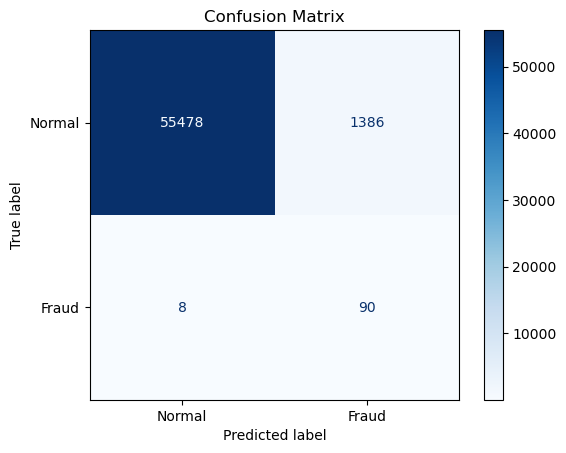

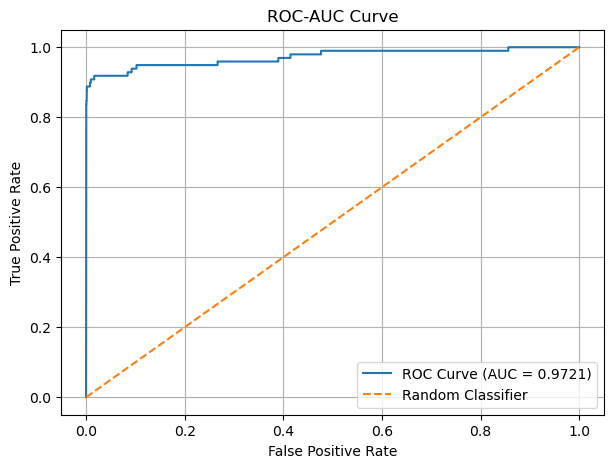

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

# 1. Load Dataset
data = pd.read_csv(r"creditcard.csv")

print("Dataset Shape:", data.shape)
print("\nClass Distribution:")
print(data["Class"].value_counts())

# 2. Separate Features and Target
X = data.drop("Class", axis=1)
y = data["Class"]

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# 4. Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Train Binary Classification Model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

print("\nTraining Logistic Regression Model...")
start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

print("Model Training Completed!")
print("Training Time:", round(end_time - start_time, 2), "seconds")

# 6. Make Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 7. Calculate Evaluation Metrics
cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n========== MODEL EVALUATION ==========")
print("\nConfusion Matrix:")
print(cm)
print("\nAccuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC Score:", round(roc_auc, 4))

# 8. Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

# 9. Plot ROC-AUC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label="ROC Curve (AUC = {:.4f})".format(roc_auc)
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve")
plt.legend()
plt.grid()
plt.show()